# 02 - Metrics tables, CDFs and KS tests
Loads saved rolling metrics (from notebook 01 or the 1505 shelves), builds the tables and CDF figures, and writes `analysis_cache.pkl` for notebooks 03 and 04.

In [1]:
import sys
from pathlib import Path
FUNCTIONS_PATH = Path("/home/mokr/Reservoir_Modelling/ML_Functions/")
if str(FUNCTIONS_PATH) not in sys.path:
    sys.path.append(str(FUNCTIONS_PATH))

import pickle, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.stats import ks_2samp

from ML_Plots import display_results_table, plot_score_cdfs, plot_cdfs, per_catchment_ks
from analysis_config import MODEL_NAME_MAP, MODEL_COLORS, AVERAGE_MODEL_COLORS, ANALYSIS_CACHE_PATH

## Load metrics

In [2]:
import shelve, gc
from analysis_config import SHELVE_METRICS_PATH

print("Loading metrics from shelve...")
with shelve.open(SHELVE_METRICS_PATH, flag="r") as db:
    no_flow_reservoir_metrics    = dict(db["no_flow_reservoir"])
    no_flow_nonreservoir_metrics = dict(db["no_flow_nonreservoir"])
gc.collect()

Loading metrics from shelve...


20

## Tables

In [3]:
# Initialize the new dictionary for the combined metrics
no_flow_grouped_metrics = {}

# Define the new model names exactly as they will appear in your final table
grouped_models = [
    "Specialist LSTMs", 
    "Hydra-LSTM: Specialists", 
    "Full LSTM",
    "Hydra-LSTM: Main", 
]

for model in grouped_models:
    no_flow_grouped_metrics[model] = {}

# Extract the list of metrics (NSE, KGE, etc.) to loop through
# This assumes all models evaluated the exact same metrics
metrics = no_flow_reservoir_metrics['Reservoir_Embedded_LSTM'].keys()

for metric in metrics:
    
    # 1. Specialist LSTMs
    # Route Reservoir LSTM to reservoir gauges, Non-Reservoir LSTM to non-reservoir gauges
    res_specialist = no_flow_reservoir_metrics['Reservoir_Embedded_LSTM'][metric]
    nonres_specialist = no_flow_nonreservoir_metrics['NonReservoir_Embedded_LSTM'][metric]
    no_flow_grouped_metrics["Specialist LSTMs"][metric] = list(res_specialist) + list(nonres_specialist)

    # 2. Hydra-LSTM: Specialists
    # Route Res-Head to reservoir gauges, Non-Res-Head to non-reservoir gauges
    # (Update the string keys here if they differ in your dictionary)
    res_hydra = no_flow_reservoir_metrics['Hydra_ResHead'][metric] 
    nonres_hydra = no_flow_nonreservoir_metrics['Hydra_NonResHead'][metric]
    no_flow_grouped_metrics["Hydra-LSTM: Specialists"][metric] = list(res_hydra) + list(nonres_hydra)

    # 3. Hydra-LSTM: Main
    # Evaluated across ALL gauges (combine both sets)
    res_main = no_flow_reservoir_metrics['Hydra_Main'][metric]
    nonres_main = no_flow_nonreservoir_metrics['Hydra_Main'][metric]
    no_flow_grouped_metrics["Hydra-LSTM: Main"][metric] = list(res_main) + list(nonres_main)

    # 4. Full LSTM
    # Evaluated across ALL gauges (combine both sets)
    res_full = no_flow_reservoir_metrics['Full_Embedded_LSTM'][metric]
    nonres_full = no_flow_nonreservoir_metrics['Full_Embedded_LSTM'][metric]
    no_flow_grouped_metrics["Full LSTM"][metric] = list(res_full) + list(nonres_full)

In [4]:
# Display the final combined table
display_results_table(
    no_flow_grouped_metrics, 
    use_median=True, 
    confidence_interval=0.95, 
    n_bootstrap=100
)

,NSE,NNSE,KGE,KGE_alpha,KGE_beta,KGE_correlation,bias
Specialist LSTMs,"0.73 [0.73, 0.73]","0.79 [0.79, 0.79]","0.78 [0.78, 0.78]","0.94 [0.94, 0.94]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","0.00 [0.00, 0.00]"
Hydra-LSTM: Specialists,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.78 [0.78, 0.78]","0.97 [0.97, 0.97]","1.01 [1.01, 1.01]","0.93 [0.93, 0.93]","0.01 [0.01, 0.01]"
Full LSTM,"0.73 [0.73, 0.73]","0.79 [0.79, 0.79]","0.76 [0.76, 0.76]","0.94 [0.94, 0.94]","1.03 [1.03, 1.03]","0.93 [0.93, 0.93]","0.04 [0.04, 0.04]"
Hydra-LSTM: Main,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.78 [0.78, 0.78]","0.97 [0.97, 0.97]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","0.00 [0.00, 0.00]"


In [5]:
display_results_table(no_flow_reservoir_metrics, use_median = True, confidence_interval=0.95, n_bootstrap=10)

,NSE,NNSE,KGE,KGE_alpha,KGE_beta,KGE_correlation,bias
Reservoir_Embedded_LSTM,"0.74 [0.74, 0.74]","0.79 [0.79, 0.79]","0.81 [0.81, 0.81]","0.94 [0.94, 0.94]","1.02 [1.02, 1.02]","0.92 [0.92, 0.92]","0.04 [0.04, 0.04]"
NonReservoir_Embedded_LSTM,"0.57 [0.57, 0.57]","0.70 [0.70, 0.70]","0.69 [0.69, 0.69]","1.06 [1.06, 1.06]","1.10 [1.10, 1.10]","0.90 [0.90, 0.90]","0.16 [0.16, 0.16]"
Full_Embedded_LSTM,"0.74 [0.74, 0.74]","0.79 [0.79, 0.80]","0.78 [0.78, 0.78]","0.94 [0.94, 0.94]","1.03 [1.03, 1.03]","0.93 [0.93, 0.93]","0.05 [0.05, 0.05]"
Hydra_Main,"0.73 [0.73, 0.73]","0.79 [0.79, 0.79]","0.80 [0.80, 0.80]","0.98 [0.98, 0.98]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","0.00 [-0.00, 0.00]"
Hydra_ResHead,"0.73 [0.73, 0.73]","0.79 [0.79, 0.79]","0.80 [0.80, 0.81]","0.98 [0.98, 0.98]","1.01 [1.01, 1.02]","0.93 [0.92, 0.93]","0.03 [0.03, 0.03]"
Hydra_NonResHead,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.80 [0.80, 0.80]","1.04 [1.04, 1.04]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","-0.01 [-0.01, -0.01]"


In [6]:
display_results_table(no_flow_nonreservoir_metrics, use_median = True, confidence_interval=0.95, n_bootstrap=100)

,NSE,NNSE,KGE,KGE_alpha,KGE_beta,KGE_correlation,bias
Reservoir_Embedded_LSTM,"0.58 [0.58, 0.58]","0.70 [0.70, 0.70]","0.63 [0.63, 0.63]","0.99 [0.98, 0.99]","0.91 [0.91, 0.91]","0.89 [0.89, 0.89]","-0.12 [-0.12, -0.11]"
NonReservoir_Embedded_LSTM,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.75 [0.75, 0.75]","0.94 [0.94, 0.94]","0.98 [0.98, 0.98]","0.93 [0.93, 0.93]","-0.03 [-0.03, -0.03]"
Full_Embedded_LSTM,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.75 [0.74, 0.75]","0.94 [0.93, 0.94]","1.03 [1.03, 1.03]","0.93 [0.93, 0.93]","0.03 [0.03, 0.03]"
Hydra_Main,"0.71 [0.71, 0.71]","0.77 [0.77, 0.77]","0.77 [0.76, 0.77]","0.96 [0.95, 0.96]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","0.00 [0.00, 0.00]"
Hydra_ResHead,"0.70 [0.70, 0.70]","0.77 [0.77, 0.77]","0.73 [0.73, 0.73]","0.99 [0.98, 0.99]","0.97 [0.97, 0.97]","0.93 [0.93, 0.93]","-0.04 [-0.05, -0.04]"
Hydra_NonResHead,"0.71 [0.71, 0.71]","0.77 [0.77, 0.77]","0.76 [0.76, 0.76]","0.97 [0.97, 0.97]","1.00 [0.99, 1.00]","0.93 [0.93, 0.93]","-0.00 [-0.01, -0.00]"


## Average per gauge

In [7]:
results_dict = {
    'no_flow_reservoir': no_flow_reservoir_metrics,
    'no_flow_nonreservoir': no_flow_nonreservoir_metrics,
}

avg_metrics_by_results = {}

for results_name, results_metrics in results_dict.items():
    avg_metrics_by_model = {}
    
    for model, metrics_data in results_metrics.items():
        df = pd.DataFrame(metrics_data)
        
        if 'init_date' in df.columns:
            df = df.drop(columns=['init_date'])
            
        if 'gauge_id' in df.columns:
            avg_df = df.groupby('gauge_id').mean(numeric_only=True)
            avg_metrics_by_model[model] = avg_df
        else:
            print(f"Notice: 'gauge_id' not found for model '{model}' in '{results_name}'. Skipping.")
    
    avg_metrics_by_results[results_name] = avg_metrics_by_model

In [8]:
avg_metrics_by_results['no_flow_reservoir']['Reservoir_Embedded_LSTM']['KGE'].to_list()

display_results_table(avg_metrics_by_results['no_flow_nonreservoir'], use_median = True, confidence_interval=0.90, n_bootstrap=1000, to_list = True)

,NSE,NNSE,KGE,KGE_alpha,KGE_beta,KGE_correlation,bias
Reservoir_Embedded_LSTM,"0.55 [0.41, 0.67]","0.71 [0.65, 0.76]","0.60 [0.18, 0.73]","0.96 [0.87, 1.54]","0.90 [0.77, 0.98]","0.86 [0.84, 0.90]","-0.08 [-0.16, -0.04]"
NonReservoir_Embedded_LSTM,"0.67 [0.55, 0.74]","0.77 [0.72, 0.81]","0.72 [0.67, 0.78]","0.92 [0.88, 0.95]","0.99 [0.94, 1.03]","0.91 [0.89, 0.93]","-0.01 [-0.13, 0.02]"
Full_Embedded_LSTM,"0.65 [0.55, 0.70]","0.76 [0.73, 0.79]","0.71 [0.62, 0.77]","0.97 [0.88, 1.04]","1.03 [1.00, 1.10]","0.90 [0.90, 0.93]","0.03 [-0.09, 0.06]"
Hydra_Main,"0.66 [0.58, 0.72]","0.76 [0.73, 0.80]","0.75 [0.68, 0.78]","0.95 [0.88, 0.98]","0.99 [0.99, 1.05]","0.90 [0.88, 0.93]","0.00 [-0.04, 0.04]"
Hydra_ResHead,"0.66 [0.54, 0.72]","0.76 [0.72, 0.81]","0.68 [0.50, 0.76]","1.01 [0.91, 1.07]","0.96 [0.90, 1.07]","0.90 [0.88, 0.93]","-0.04 [-0.12, 0.05]"
Hydra_NonResHead,"0.66 [0.58, 0.73]","0.76 [0.73, 0.80]","0.75 [0.66, 0.77]","0.98 [0.92, 1.00]","1.00 [0.97, 1.03]","0.90 [0.89, 0.93]","-0.01 [-0.08, 0.03]"


## CDFs

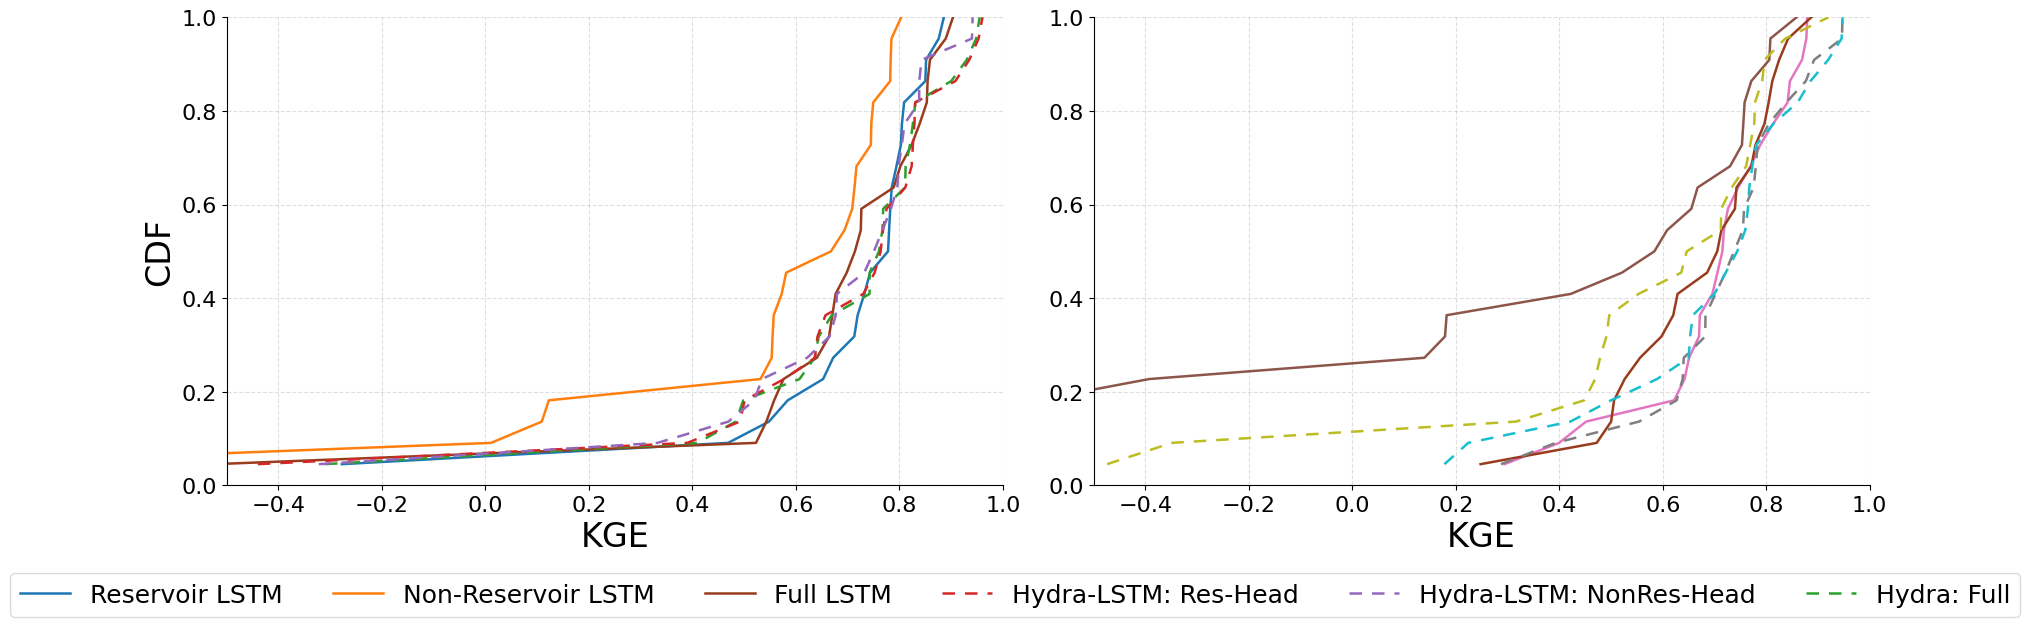

In [9]:
display_names = list(MODEL_NAME_MAP.values())

CDFS = plot_cdfs(
    avg_metrics_by_results,
    title_names=[
        "Reservoir Gauges",
        "Non Reservoir Gauges",
    ],
    model_names=display_names,   # ← these now match MODEL_COLORS keys
    model_colors=MODEL_COLORS, 
    xlim = -0.5,
)

In [10]:
merged_metrics_by_results = {}

model_mapping = {
    "Specialist":       ("Reservoir_Embedded_LSTM",    "NonReservoir_Embedded_LSTM"),
    "Full LSTM":        ("Full_Embedded_LSTM",          "Full_Embedded_LSTM"),
    "Hydra Specialist": ("Hydra_ResHead",               "Hydra_NonResHead"),
    "Hydra: Main":      ("Hydra_Main",                  "Hydra_Main"),
}

merged_metrics_by_results["all_gauges"] = {
    display_name: pd.concat([
        avg_metrics_by_results["no_flow_reservoir"][res_key],
        avg_metrics_by_results["no_flow_nonreservoir"][nonres_key],
    ])
    for display_name, (res_key, nonres_key) in model_mapping.items()
}

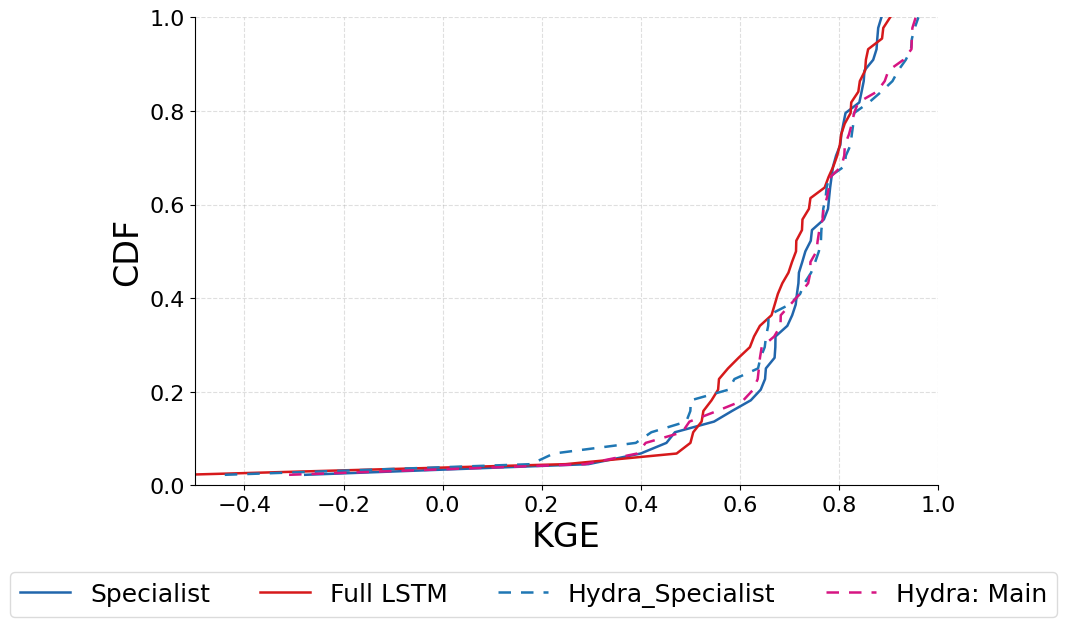

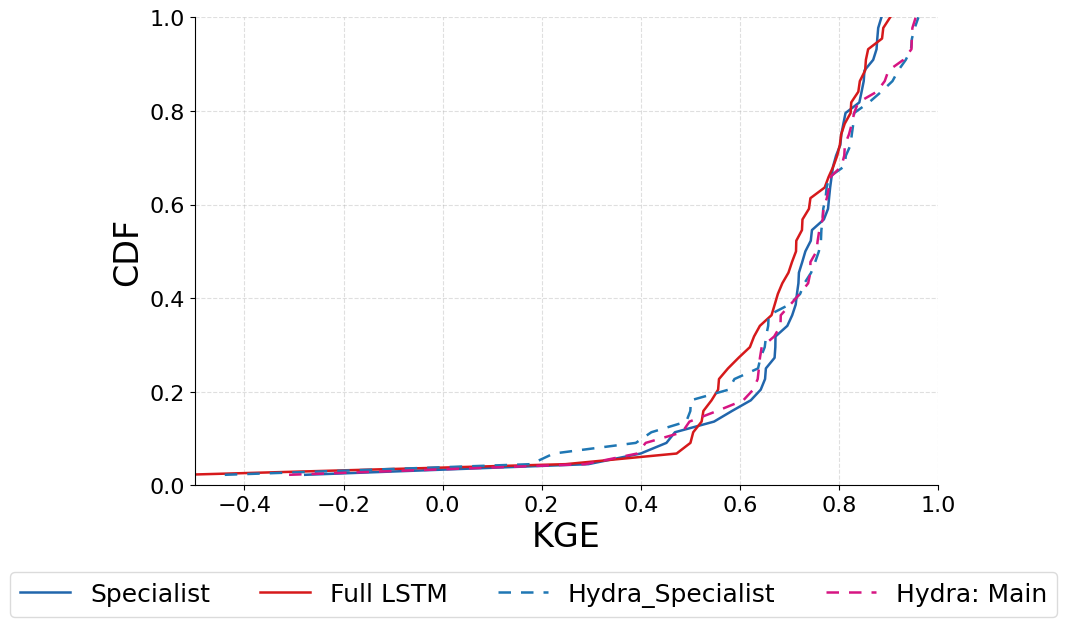

In [11]:
plot_cdfs(
    merged_metrics_by_results,
    title_names=[
        "All Gauges"
    ],
    model_names= ['Specialist', 'Full LSTM', 'Hydra_Specialist', 'Hydra: Main'],   # ← these now match MODEL_COLORS keys
    model_colors=AVERAGE_MODEL_COLORS,
    xlim = -0.5,
)

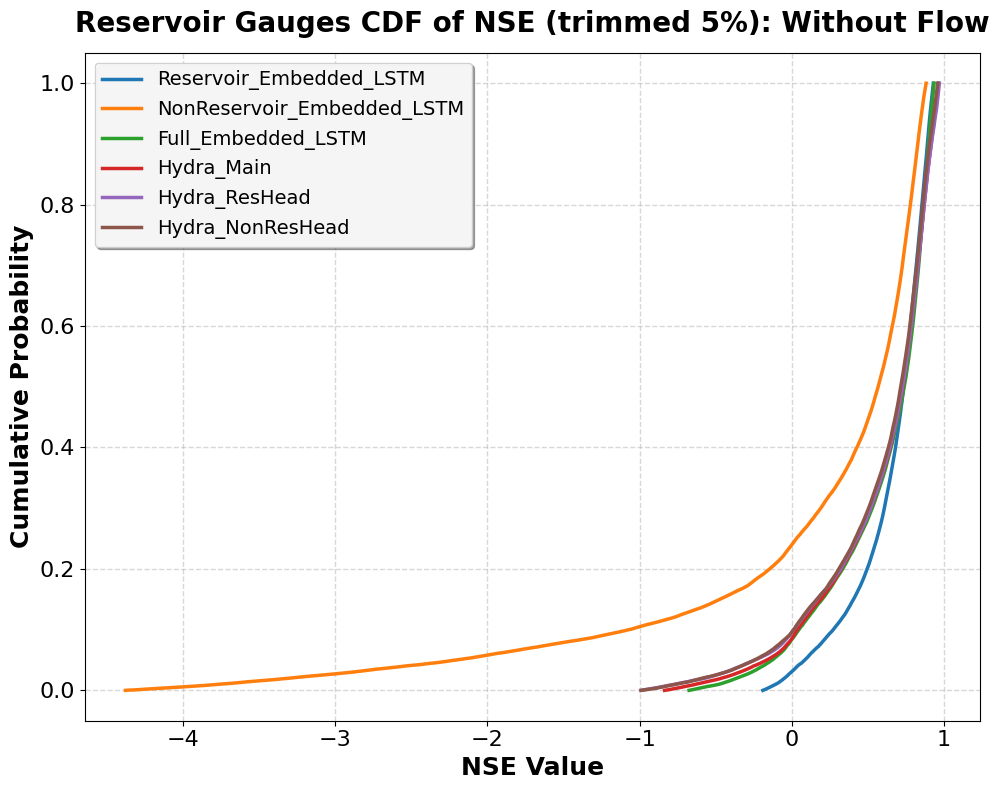

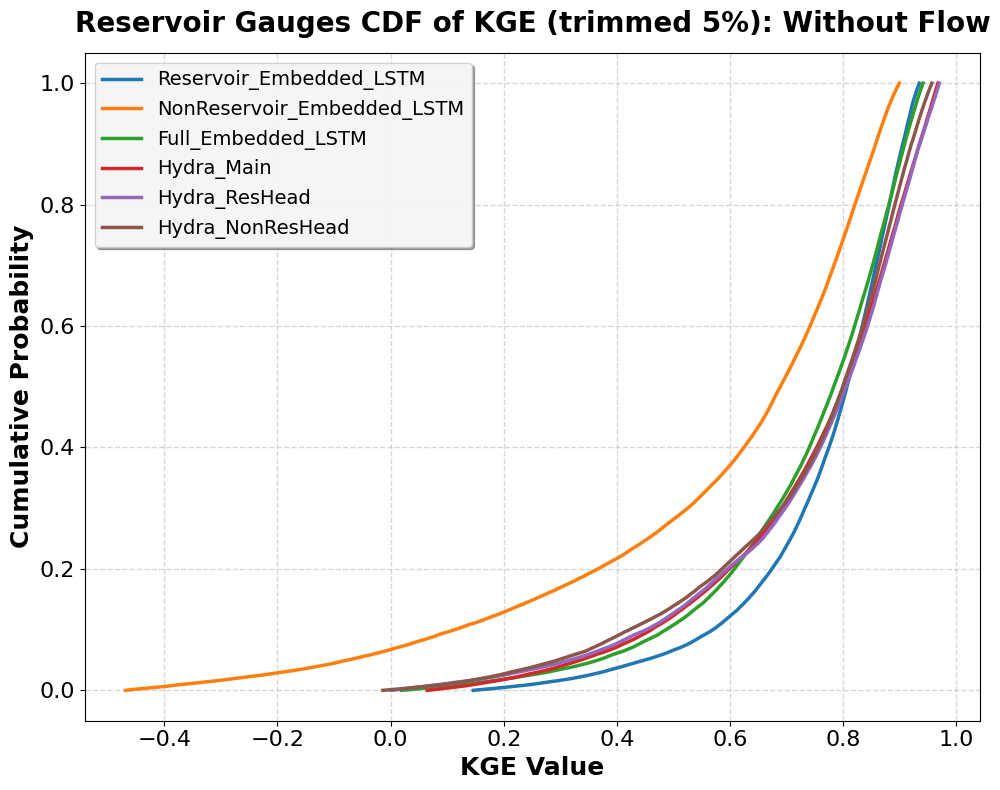

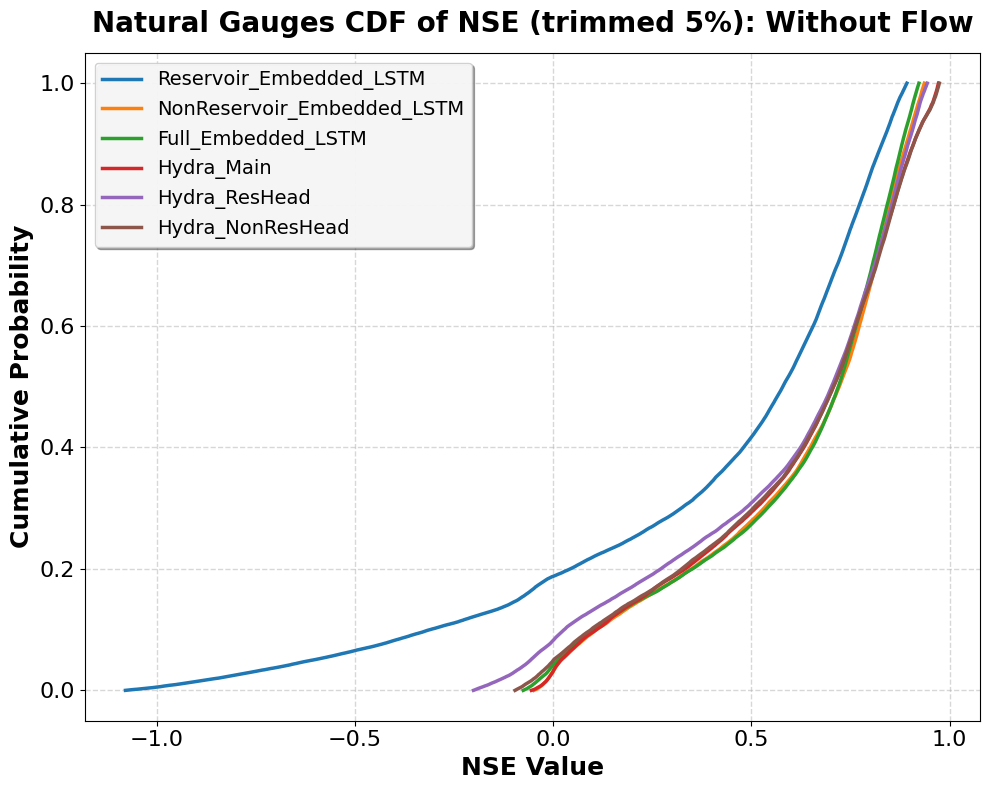

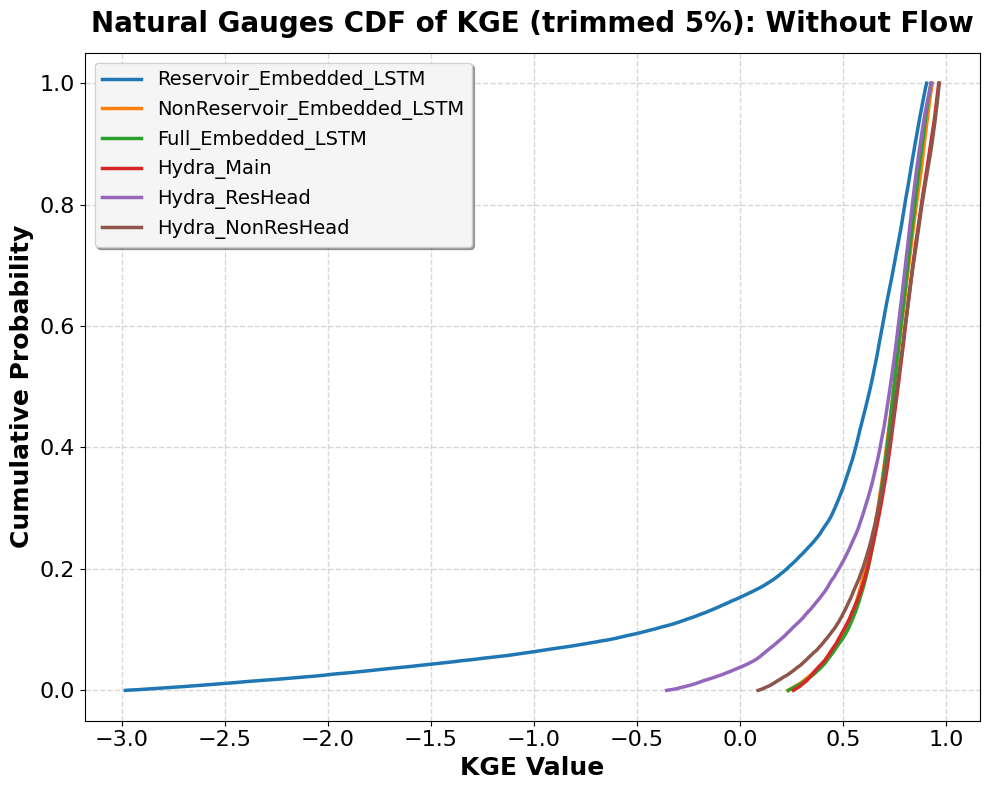

In [19]:
score_types = ["NSE", "KGE"]
Trim = 5

plot_score_cdfs(results_dict['no_flow_reservoir'],    Trim, MODEL_NAME_MAP, catchment_type="Reservoir", flow_type="Without Flow", score_types=score_types)
plot_score_cdfs(results_dict['no_flow_nonreservoir'], Trim, MODEL_NAME_MAP, catchment_type="Natural",   flow_type="Without Flow", score_types=score_types)

## KS tests (not in the paper, but the numbers are cited)
Two-sample KS on per-gauge KGE for every pair of models. `per_catchment_ks` now lives in `ML_Plots`.

In [13]:
ks_model_names = list(avg_metrics_by_results['no_flow_nonreservoir'].keys())
per_catchment_ks(avg_metrics_by_results['no_flow_nonreservoir'], ks_model_names, metric='KGE')

,Model 1,Model 2,KS Statistic,p-value
0,Reservoir_Embedded_LSTM,NonReservoir_Embedded_LSTM,0.409091,0.049347
1,Reservoir_Embedded_LSTM,Hydra_Main,0.409091,0.049347
2,Reservoir_Embedded_LSTM,Full_Embedded_LSTM,0.363636,0.109262
3,Reservoir_Embedded_LSTM,Hydra_NonResHead,0.318182,0.218368
4,Hydra_Main,Hydra_ResHead,0.318182,0.218368
5,Reservoir_Embedded_LSTM,Hydra_ResHead,0.272727,0.393740
6,Full_Embedded_LSTM,Hydra_ResHead,0.272727,0.393740
7,NonReservoir_Embedded_LSTM,Hydra_ResHead,0.272727,0.393740
8,Hydra_ResHead,Hydra_NonResHead,0.272727,0.393740
9,NonReservoir_Embedded_LSTM,Full_Embedded_LSTM,0.227273,0.632386


In [14]:
per_catchment_ks(avg_metrics_by_results['no_flow_reservoir'], ks_model_names, metric='KGE')

,Model 1,Model 2,KS Statistic,p-value
0,NonReservoir_Embedded_LSTM,Hydra_Main,0.409091,0.049347
1,NonReservoir_Embedded_LSTM,Hydra_ResHead,0.409091,0.049347
2,Reservoir_Embedded_LSTM,NonReservoir_Embedded_LSTM,0.363636,0.109262
3,NonReservoir_Embedded_LSTM,Full_Embedded_LSTM,0.363636,0.109262
4,NonReservoir_Embedded_LSTM,Hydra_NonResHead,0.363636,0.109262
5,Reservoir_Embedded_LSTM,Hydra_ResHead,0.227273,0.632386
6,Reservoir_Embedded_LSTM,Full_Embedded_LSTM,0.227273,0.632386
7,Reservoir_Embedded_LSTM,Hydra_Main,0.227273,0.632386
8,Full_Embedded_LSTM,Hydra_ResHead,0.227273,0.632386
9,Full_Embedded_LSTM,Hydra_Main,0.227273,0.632386


## Hand-off to notebooks 03 and 04

In [15]:
with open(ANALYSIS_CACHE_PATH, "wb") as f:
    pickle.dump({"avg_metrics_by_results": avg_metrics_by_results,
                 "merged_metrics_by_results": merged_metrics_by_results}, f)